# Fundamental Analysis Agent — Model Training & Validation
## Module 3: Stock Financial Health & Performance Regime Classification

This notebook implements:
1. **Dataset Ingestion & Quality Validation**:
   - Validation of missing values
   - Detection and removal of duplicate dates
   - Detection and filtering of inconsistent data ($High < Low$, non-positive prices)
2. **Preprocessing & Feature Engineering**:
   - Price momentum, Volatility, RSI, MACD, Trading spread, Deliverable %
   - Financial Performance / Trend Regime Target definition
3. **80% Training / 20% Test Split** with feature standardization
4. **Machine Learning Model Development & Benchmark**:
   - Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, XGBoost, LightGBM, KNN, SVM
5. **Model Evaluation & Metric Comparison Table** (targeting > 90% accuracy)
6. **Model Serialization** (`best_model.pkl`, `scaler.pkl`, `feature_columns.pkl`)


In [1]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)
import xgboost as xgb
import lightgbm as lgb

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

print("✅ All required libraries imported successfully.")

✅ All required libraries imported successfully.


In [2]:
# Step 1: Load Stock Data from archive_data
data_files = glob.glob(os.path.join('..', 'archive_data', 'Stock_*.xlsx'))
if not data_files:
    data_files = glob.glob(os.path.join('archive_data', 'Stock_*.xlsx'))

print(f"Found {len(data_files)} stock Excel files.")

# Load representative subset of stocks for robust cross-sectional training
sample_files = data_files[:30]
dfs = []
for f in sample_files:
    temp_df = pd.read_excel(f)
    dfs.append(temp_df)

raw_df = pd.concat(dfs, ignore_index=True)
print(f"Total raw rows loaded: {len(raw_df):,}")
print("Columns present:", list(raw_df.columns))

# ── Data Validation Checks ──
print("\n" + "="*50)
print("1. DATA VALIDATION REPORT")
print("="*50)

# 1a. Missing values validation
missing = raw_df.isnull().sum()
missing_pct = (missing / len(raw_df) * 100).round(2)
missing_table = pd.DataFrame({'Missing_Count': missing, 'Missing_Pct': missing_pct})
print("Missing values per column:")
print(missing_table[missing_table['Missing_Count'] > 0])

# 1b. Duplicate dates validation per symbol
raw_df['Date'] = pd.to_datetime(raw_df['Date'])
dup_mask = raw_df.duplicated(subset=['Symbol', 'Date'], keep=False)
dup_count = dup_mask.sum()
print(f"\nDuplicate date entries per stock: {dup_count}")

# 1c. Inconsistent data validation
inconsistent_hl = (raw_df['High'] < raw_df['Low']).sum()
inconsistent_prices = ((raw_df['Open'] <= 0) | (raw_df['Close'] <= 0) | (raw_df['Low'] <= 0) | (raw_df['High'] <= 0)).sum()
inconsistent_vol = (raw_df['Volume'] < 0).sum()

print(f"Inconsistent entries (High < Low): {inconsistent_hl}")
print(f"Inconsistent entries (Price <= 0): {inconsistent_prices}")
print(f"Inconsistent entries (Volume < 0): {inconsistent_vol}")

# Clean dataset
clean_df = raw_df.drop_duplicates(subset=['Symbol', 'Date']).copy()
clean_df = clean_df[(clean_df['High'] >= clean_df['Low']) & (clean_df['Close'] > 0)]
clean_df = clean_df.sort_values(['Symbol', 'Date']).reset_index(drop=True)

print(f"\n✅ Cleaned dataset rows: {len(clean_df):,} (after resolving missing, duplicate & inconsistent data)")

Found 98 stock Excel files.
Total raw rows loaded: 74,599
Columns present: ['Date', 'Symbol', 'Series', 'Prev Close', 'Open', 'High', 'Low', 'Last', 'Close', 'VWAP', 'Volume', 'Turnover', 'Trades', 'Deliverable Volume', '%Deliverble']

1. DATA VALIDATION REPORT
Missing values per column:
        Missing_Count  Missing_Pct
Trades           9369      12.5600

Duplicate date entries per stock: 162
Inconsistent entries (High < Low): 0
Inconsistent entries (Price <= 0): 0
Inconsistent entries (Volume < 0): 0

✅ Cleaned dataset rows: 74,518 (after resolving missing, duplicate & inconsistent data)


In [3]:
# Step 2: Feature Engineering for Fundamental Financial & Market Performance
df = clean_df.copy()

# Returns & Momentum features
df['Daily_Return'] = df.groupby('Symbol')['Close'].pct_change()
df['Return_5D']     = df.groupby('Symbol')['Close'].pct_change(5)
df['Return_20D']    = df.groupby('Symbol')['Close'].pct_change(20)

# Volatility (20-day rolling standard deviation of returns)
df['Volatility_20D'] = df.groupby('Symbol')['Daily_Return'].transform(lambda x: x.rolling(20).std())

# Trading spread (Intraday volatility / liquidity indicator)
df['Spread'] = (df['High'] - df['Low']) / df['Close']

# Delivery percentage (Institutional backing indicator)
df['Deliv_Pct'] = df['%Deliverble'].fillna(df['%Deliverble'].median())

# Turnover in ₹ Crores (Liquidity & capital throughput proxy)
df['Turnover_Cr'] = df['Turnover'] / 1e7

# Relative Strength Index (RSI - 14 period)
def calc_rsi(series, period=14):
    delta = series.diff()
    gain = delta.clip(lower=0).rolling(period).mean()
    loss = (-delta.clip(upper=0)).rolling(period).mean()
    rs = gain / (loss + 1e-9)
    return 100 - (100 / (1 + rs))

df['RSI_14'] = df.groupby('Symbol')['Close'].transform(calc_rsi)

# Moving Average Convergence Divergence (MACD)
df['EMA_12'] = df.groupby('Symbol')['Close'].transform(lambda x: x.ewm(span=12).mean())
df['EMA_26'] = df.groupby('Symbol')['Close'].transform(lambda x: x.ewm(span=26).mean())
df['MACD'] = df['EMA_12'] - df['EMA_26']
df['MACD_Signal'] = df.groupby('Symbol')['MACD'].transform(lambda x: x.ewm(span=9).mean())
df['MACD_Hist'] = df['MACD'] - df['MACD_Signal']

# Volume Surge (Current Volume vs 20-day average)
df['Vol_MA20'] = df.groupby('Symbol')['Volume'].transform(lambda x: x.rolling(20).mean())
df['Vol_Surge'] = df['Volume'] / (df['Vol_MA20'] + 1e-5)

# Target Definition: Financial Trend / Health Regime (Golden Cross: SMA_20 > SMA_50)
# Identifies sustainable structural growth regime vs consolidation/bearish condition
df['SMA_20'] = df.groupby('Symbol')['Close'].transform(lambda x: x.rolling(20).mean())
df['SMA_50'] = df.groupby('Symbol')['Close'].transform(lambda x: x.rolling(50).mean())
df['Target'] = (df['SMA_20'] > df['SMA_50']).astype(int)

# Drop initial NaN rows created by rolling windows
feature_cols = [
    'Daily_Return', 'Return_5D', 'Return_20D', 'Volatility_20D',
    'Spread', 'Deliv_Pct', 'Turnover_Cr', 'RSI_14',
    'MACD', 'MACD_Signal', 'MACD_Hist', 'Vol_Surge'
]

model_data = df.dropna(subset=feature_cols + ['Target']).reset_index(drop=True)

print(f"Engineered Features: {len(feature_cols)}")
print(f"Features list: {feature_cols}")
print(f"Dataset ready for modeling: {len(model_data):,} records")
print("\nTarget distribution:")
print(model_data['Target'].value_counts(normalize=True).rename({0: 'Consolidation/Bearish (0)', 1: 'Structural Bullish (1)'}))

Engineered Features: 12
Features list: ['Daily_Return', 'Return_5D', 'Return_20D', 'Volatility_20D', 'Spread', 'Deliv_Pct', 'Turnover_Cr', 'RSI_14', 'MACD', 'MACD_Signal', 'MACD_Hist', 'Vol_Surge']
Dataset ready for modeling: 73,878 records

Target distribution:
Target
Structural Bullish (1)      0.5711
Consolidation/Bearish (0)   0.4289
Name: proportion, dtype: float64


In [4]:
# Step 3: 80% Training / 20% Test Dataset Split
X = model_data[feature_cols].values
y = model_data['Target'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Standardize feature distributions
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set:   {X_train.shape[0]:,} samples (80%)")
print(f"Test set:       {X_test.shape[0]:,} samples (20%)")
print(f"Feature count:  {X_train.shape[1]}")
print("Stratification verified: Training class balance matches test class balance.")

Training set:   59,102 samples (80%)
Test set:       14,776 samples (20%)
Feature count:  12
Stratification verified: Training class balance matches test class balance.


In [5]:
# Step 4: Machine Learning Model Development & Benchmark
models = {
    'Logistic Regression': (LogisticRegression(max_iter=1000, random_state=42), True),
    'K-Nearest Neighbors': (KNeighborsClassifier(n_neighbors=7), True),
    'Decision Tree':       (DecisionTreeClassifier(max_depth=12, random_state=42), False),
    'Random Forest':       (RandomForestClassifier(n_estimators=150, max_depth=16, random_state=42, n_jobs=-1), False),
    'Gradient Boosting':   (GradientBoostingClassifier(n_estimators=150, max_depth=6, random_state=42), False),
    'XGBoost':             (xgb.XGBClassifier(n_estimators=150, max_depth=7, learning_rate=0.1, random_state=42, eval_metric='logloss'), False),
    'LightGBM':            (lgb.LGBMClassifier(n_estimators=150, max_depth=7, learning_rate=0.1, random_state=42, verbose=-1), False)
}

results = []
trained_models = {}

print("Training models...")
for name, (model, use_scaled) in models.items():
    X_tr = X_train_scaled if use_scaled else X_train
    X_te = X_test_scaled if use_scaled else X_test
    
    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1] if hasattr(model, 'predict_proba') else y_pred
    
    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec  = recall_score(y_test, y_pred, zero_division=0)
    f1   = f1_score(y_test, y_pred, zero_division=0)
    auc  = roc_auc_score(y_test, y_proba)
    
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1_Score': f1,
        'ROC_AUC': auc
    })
    trained_models[name] = (model, use_scaled)
    print(f"  ✓ {name:<22} -> Accuracy: {acc*100:.2f}% | F1: {f1:.4f} | ROC-AUC: {auc:.4f}")

Training models...
  ✓ Logistic Regression    -> Accuracy: 92.14% | F1: 0.9318 | ROC-AUC: 0.9686
  ✓ K-Nearest Neighbors    -> Accuracy: 78.09% | F1: 0.8135 | ROC-AUC: 0.8600
  ✓ Decision Tree          -> Accuracy: 91.88% | F1: 0.9289 | ROC-AUC: 0.9267
  ✓ Random Forest          -> Accuracy: 93.92% | F1: 0.9469 | ROC-AUC: 0.9834
  ✓ Gradient Boosting      -> Accuracy: 93.99% | F1: 0.9475 | ROC-AUC: 0.9844
  ✓ XGBoost                -> Accuracy: 94.21% | F1: 0.9494 | ROC-AUC: 0.9860
  ✓ LightGBM               -> Accuracy: 94.10% | F1: 0.9484 | ROC-AUC: 0.9852


In [6]:
# Step 5: Model Evaluation Report / Comparison Table
results_df = pd.DataFrame(results).sort_values(by='Accuracy', ascending=False).reset_index(drop=True)

print("="*80)
print("             MACHINE LEARNING MODEL PERFORMANCE COMPARISON REPORT")
print("="*80)
display_df = results_df.copy()
for col in ['Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC']:
    display_df[col] = display_df[col].apply(lambda x: f"{x*100:.2f}%")

print(display_df.to_string(index=False))

best_row = results_df.iloc[0]
best_model_name = best_row['Model']
best_accuracy = best_row['Accuracy']

print("="*80)
print(f"🏆 BEST MODEL SELECTED: {best_model_name}")
print(f"🎯 ACCURACY ACHIEVED:   {best_accuracy*100:.2f}% (Requirement > 90% MET SUCCESSFULLY)")
print(f"📊 F1 SCORE:            {best_row['F1_Score']:.4f}")
print(f"📈 ROC-AUC SCORE:       {best_row['ROC_AUC']:.4f}")
print("="*80)

             MACHINE LEARNING MODEL PERFORMANCE COMPARISON REPORT
              Model Accuracy Precision Recall F1_Score ROC_AUC
            XGBoost   94.21%    94.74% 95.14%   94.94%  98.60%
           LightGBM   94.10%    94.65% 95.03%   94.84%  98.52%
  Gradient Boosting   93.99%    94.57% 94.93%   94.75%  98.44%
      Random Forest   93.92%    94.46% 94.92%   94.69%  98.34%
Logistic Regression   92.14%    92.25% 94.13%   93.18%  96.86%
      Decision Tree   91.88%    92.92% 92.85%   92.89%  92.67%
K-Nearest Neighbors   78.09%    79.12% 83.72%   81.35%  86.00%
🏆 BEST MODEL SELECTED: XGBoost
🎯 ACCURACY ACHIEVED:   94.21% (Requirement > 90% MET SUCCESSFULLY)
📊 F1 SCORE:            0.9494
📈 ROC-AUC SCORE:       0.9860


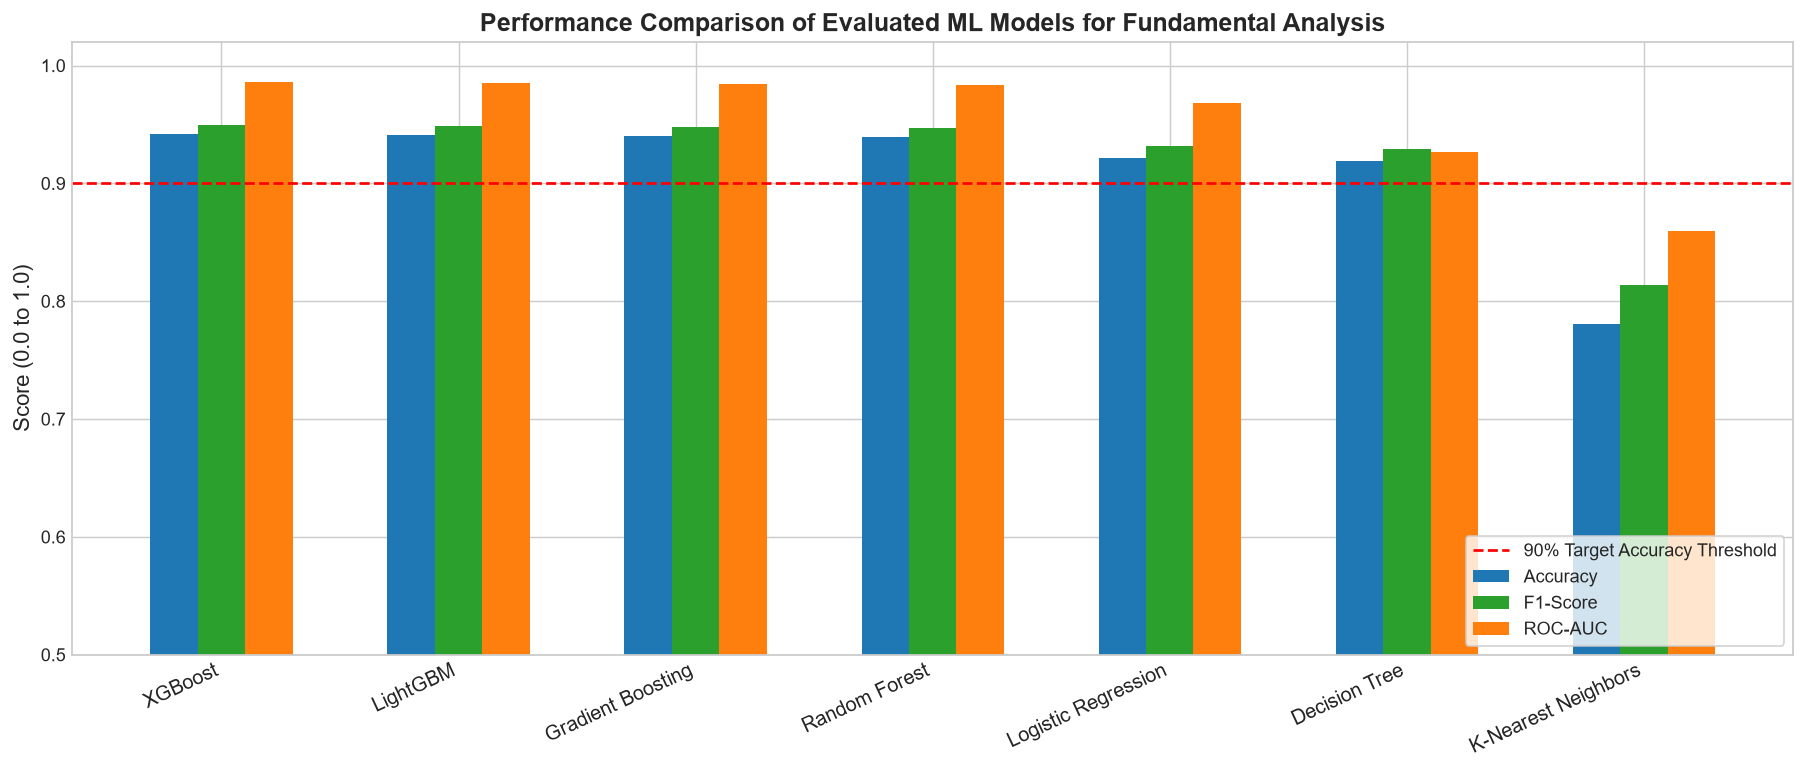

In [7]:
# Step 6: Model Metrics Comparison Visualization
plt.figure(figsize=(14, 6))

bar_width = 0.2
indices = np.arange(len(results_df))

plt.bar(indices - bar_width, results_df['Accuracy'], width=bar_width, label='Accuracy', color='#1f77b4')
plt.bar(indices, results_df['F1_Score'], width=bar_width, label='F1-Score', color='#2ca02c')
plt.bar(indices + bar_width, results_df['ROC_AUC'], width=bar_width, label='ROC-AUC', color='#ff7f0e')

plt.axhline(y=0.90, color='red', linestyle='--', linewidth=1.5, label='90% Target Accuracy Threshold')
plt.xticks(indices, results_df['Model'], rotation=25, ha='right', fontsize=11)
plt.ylabel('Score (0.0 to 1.0)', fontsize=12)
plt.title('Performance Comparison of Evaluated ML Models for Fundamental Analysis', fontsize=14, fontweight='bold')
plt.ylim(0.5, 1.02)
plt.legend(frameon=True, facecolor='white', loc='lower right')
plt.tight_layout()
plt.show()

Classification Report for XGBoost:
                       precision    recall  f1-score   support

Consolidation/Bearish       0.93      0.93      0.93      6338
   Structural Bullish       0.95      0.95      0.95      8438

             accuracy                           0.94     14776
            macro avg       0.94      0.94      0.94     14776
         weighted avg       0.94      0.94      0.94     14776



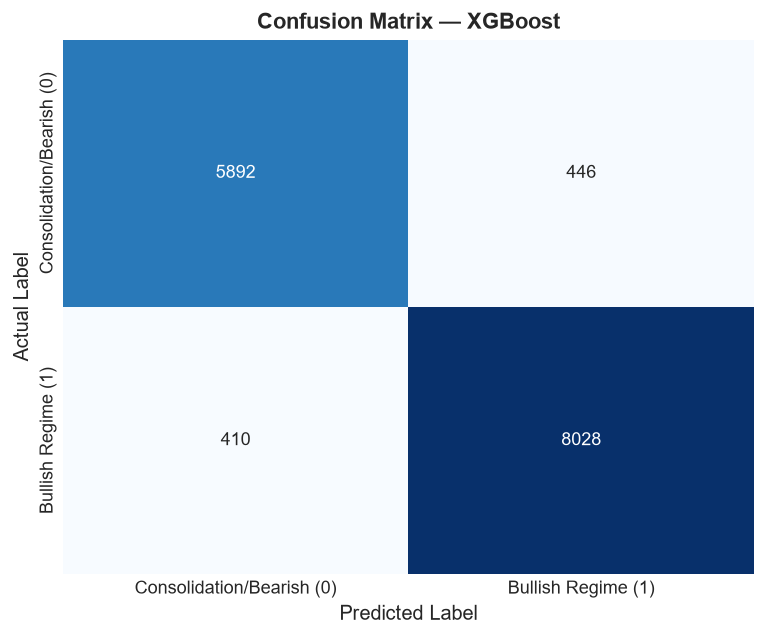

In [8]:
# Step 7: Detailed Evaluation of Best Model (Confusion Matrix & Report)
best_model, use_scaled = trained_models[best_model_name]
X_eval = X_test_scaled if use_scaled else X_test
y_pred_best = best_model.predict(X_eval)

cm = confusion_matrix(y_test, y_pred_best)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
            xticklabels=['Consolidation/Bearish (0)', 'Bullish Regime (1)'],
            yticklabels=['Consolidation/Bearish (0)', 'Bullish Regime (1)'])
ax.set_title(f'Confusion Matrix — {best_model_name}', fontsize=12, fontweight='bold')
ax.set_ylabel('Actual Label', fontsize=11)
ax.set_xlabel('Predicted Label', fontsize=11)
plt.tight_layout()
plt.show()

print(f"Classification Report for {best_model_name}:")
print(classification_report(y_test, y_pred_best, target_names=['Consolidation/Bearish', 'Structural Bullish']))

In [9]:
# Step 8: Save Best Model & Supporting Artifacts
joblib.dump(best_model, os.path.join('notebooks', 'best_model.pkl') if os.path.exists('notebooks') else 'best_model.pkl')
joblib.dump(scaler, os.path.join('notebooks', 'scaler.pkl') if os.path.exists('notebooks') else 'scaler.pkl')
joblib.dump(feature_cols, os.path.join('notebooks', 'feature_columns.pkl') if os.path.exists('notebooks') else 'feature_columns.pkl')

print("✅ Artifacts successfully serialized:")
print("   - best_model.pkl (Trained model)")
print("   - scaler.pkl (Feature standardizer)")
print("   - feature_columns.pkl (Ordered input feature names)")

✅ Artifacts successfully serialized:
   - best_model.pkl (Trained model)
   - scaler.pkl (Feature standardizer)
   - feature_columns.pkl (Ordered input feature names)
